# Online Machine Learning with River 

In [1]:
from river import datasets, linear_model, metrics, preprocessing, optim, evaluate, compose, tree, forest, neighbors, drift, utils
from river.datasets import synth
import itertools
import time
import matplotlib.pyplot as plt

In [2]:
# Helper function to inspect features metadata 

x, y = next(iter(datasets.SP500Stocks()))

for k, v in x.items():
    print(f"{k:<20} {type(v).__name__:<10} {v}")
print(f"{'TARGET':<20} {type(y).__name__:<10} {y}")

AAPL                 float      1.042235
AMZN                 float      -1.809506
IBM                  float      -0.753669
INTC                 float      0.142857
JNJ                  float      -0.09274
JPM                  float      0.06169
KO                   float      -0.41269
MSFT                 float      1.125227
WMT                  float      -0.111919
XOM                  float      -0.372418
TARGET               float      -0.216671


## REGRESSION
---

### ETL

In [2]:
# 4 datasets, 3 real & 1 synthetic, capped at 100000 rows 
taxis    = list(itertools.islice(datasets.Taxis(), 10_000))
bikes    = list(itertools.islice(datasets.Bikes(), 10_000))
stocks   = list(itertools.islice(datasets.SP500Stocks(), 10_000))
friedman = list(synth.FriedmanDrift(drift_type='gra', position=(3_000, 7_000), seed=42).take(10_000))

In [3]:
# Preprocessing custom functions for each dataset

# Taxis 
def date_preprocess_taxis(x):
    m = x['pickup_datetime']
    return {'hour': m.hour, 'weekday': m.weekday(), 'is_weekend': int(m.weekday() >= 5)}

def taxis_features():
    return (
        compose.FuncTransformer(date_preprocess_taxis)
        + compose.Select('passenger_count', 'pickup_latitude', 'pickup_longitude',
                         'dropoff_latitude', 'dropoff_longitude')
        + (compose.Select('vendor_id', 'store_and_fwd_flag') | preprocessing.OneHotEncoder())
    )

# Bikes 
def date_preprocess_bikes(x):
    m = x['moment']
    return {'hour': m.hour, 'weekday': m.weekday(), 'is_weekend': int(m.weekday() >= 5)}

def bikes_features():
    return (
        compose.FuncTransformer(date_preprocess_bikes)
        + compose.Select('clouds', 'humidity', 'pressure', 'temperature', 'wind')
        + (compose.Select('station', 'description') | preprocessing.OneHotEncoder())
    )

# Stocks
def stocks_features():
    return compose.Select('AAPL', 'AMZN', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'MSFT', 'WMT', 'XOM')

# Friedman
def friedman_features():
    return compose.FuncTransformer(lambda x: x)

In [4]:
streams = {
    'taxis': {'stream': taxis, 'features_processor': taxis_features},
    'bikes': {'stream': bikes, 'features_processor': bikes_features},
    'stocks': {'stream': stocks, 'features_processor': stocks_features},
    'friedman': {'stream': friedman, 'features_processor': friedman_features}
}

In [7]:
regression_benchmark = {'LinearRegression': {},
                        'HoeffdingAdaptiveTree': {}, 
                        'AdaptiveRandomForest': {},
                        'PassiveAgressiveRegressor': {},
                        }

### Linear Regression

In [8]:
for name, params in streams.items(): 
    mae, rmse, r2 = metrics.MAE(), metrics.RMSE(), metrics.R2()
    lin_reg_model = compose.Pipeline(
        params['features_processor'](),
        preprocessing.StandardScaler(),
        preprocessing.TargetStandardScaler(
            linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01))
        )
    )

    start = time.time()
    evaluate.progressive_val_score(params['stream'], lin_reg_model, mae + rmse + r2)
    print(f"Linear Model on {name}: MAE = {mae}, RMSE = {rmse}, R2 = {r2}")
    print(f"Runtime: {time.time() - start}s")

    regression_benchmark['LinearRegression'][name] = {
        'MAE': mae.get(),
        'RMSE': rmse.get(),
        'R2': r2.get(),
        'time_s': time.time() - start,
    }

Linear Model on taxis: MAE = MAE: 776.732387, RMSE = RMSE: 3,951.84289, R2 = R2: -0.064508
Runtime: 0.34220218658447266s
Linear Model on bikes: MAE = MAE: 1.514011, RMSE = RMSE: 2.069504, R2 = R2: 0.926069
Runtime: 0.4060971736907959s
Linear Model on stocks: MAE = MAE: 0.587302, RMSE = RMSE: 0.816393, R2 = R2: -0.092034
Runtime: 0.027370929718017578s
Linear Model on friedman: MAE = MAE: 2.180526, RMSE = RMSE: 2.808599, R2 = R2: 0.676754
Runtime: 0.2044210433959961s


### Tree Based : Hoeffding Adaptive Tree

In [9]:
for name, params in streams.items(): 
    mae, rmse, r2 = metrics.MAE(), metrics.RMSE(), metrics.R2()
    hat_model = compose.Pipeline(
        params['features_processor'](),
        preprocessing.StandardScaler(),
        tree.HoeffdingAdaptiveTreeRegressor(seed=42)
    )

    start = time.time()
    evaluate.progressive_val_score(params['stream'], hat_model, mae + rmse + r2)
    print(f"HAT Model: MAE = {mae}, RMSE = {rmse}, R2 = {r2}")
    print(f"Runtime: {time.time() - start}s")

    regression_benchmark['HoeffdingAdaptiveTree'][name] = {
        'MAE': mae.get(),
        'RMSE': rmse.get(),
        'R2': r2.get(),
        'time_s': time.time() - start,
    }

HAT Model: MAE = MAE: 605.486611, RMSE = RMSE: 4,380.895367, R2 = R2: -0.308203
Runtime: 0.9123260974884033s
HAT Model: MAE = MAE: 1.80006, RMSE = RMSE: 3.578439, R2 = R2: 0.778953
Runtime: 0.8526592254638672s
HAT Model: MAE = MAE: 0.570674, RMSE = RMSE: 0.791272, R2 = R2: -0.025862
Runtime: 0.09353899955749512s
HAT Model: MAE = MAE: 2.16629, RMSE = RMSE: 2.810543, R2 = R2: 0.676307
Runtime: 2.7210800647735596s


### Ensemble Based : Adaptive Random Forest

In [10]:
for name, params in streams.items(): 
    mae, rmse, r2 = metrics.MAE(), metrics.RMSE(), metrics.R2()
    arf_model = compose.Pipeline(
        params['features_processor'](),
        preprocessing.StandardScaler(),
        preprocessing.TargetStandardScaler(
        forest.ARFRegressor(seed=42))
    )
    
    start = time.time()
    evaluate.progressive_val_score(params['stream'], arf_model, mae + rmse + r2)
    print(f"ARF Model: MAE = {mae}, RMSE = {rmse}, R2 = {r2}")
    print(f"Runtime: {time.time() - start}s")


    regression_benchmark['AdaptiveRandomForest'][name] = {
        'MAE': mae.get(),
        'RMSE': rmse.get(),
        'R2': r2.get(),
        'time_s': time.time() - start,
    }

ARF Model: MAE = MAE: 460.58161, RMSE = RMSE: 3,824.899947, R2 = R2: 0.002783
Runtime: 7.236968994140625s
ARF Model: MAE = MAE: 4.038793, RMSE = RMSE: 5.581006, R2 = R2: 0.462323
Runtime: 6.054051637649536s
ARF Model: MAE = MAE: 0.575001, RMSE = RMSE: 0.802212, R2 = R2: -0.054427
Runtime: 1.032668113708496s
ARF Model: MAE = MAE: 2.49763, RMSE = RMSE: 3.193337, R2 = R2: 0.582129
Runtime: 9.864737749099731s


#### Passive Agressive PAR Regressor 

In [11]:
for name, params in streams.items(): 
    mae, rmse, r2 = metrics.MAE(), metrics.RMSE(), metrics.R2()
    par_model = compose.Pipeline(
        params['features_processor'](),
        preprocessing.StandardScaler(),
        preprocessing.TargetStandardScaler(
            linear_model.PARegressor(C=0.01, mode=2, eps=0.1))
    )
    
    start = time.time()
    evaluate.progressive_val_score(params['stream'], par_model, mae + rmse + r2)
    print(f"KNN Regressor: MAE = {mae}, RMSE = {rmse}, R2 = {r2}")
    print(f"Runtime: {time.time() - start}s")

    regression_benchmark['PassiveAgressiveRegressor'][name] = {
        'MAE': mae.get(),
        'RMSE': rmse.get(),
        'R2': r2.get(),
        'time_s': time.time() - start,
    }

KNN Regressor: MAE = MAE: 1,290.973687, RMSE = RMSE: 4,622.305957, R2 = R2: -0.456353
Runtime: 0.29825901985168457s
KNN Regressor: MAE = MAE: 2.716364, RMSE = RMSE: 3.5789, R2 = R2: 0.778896
Runtime: 0.38105106353759766s
KNN Regressor: MAE = MAE: 0.757094, RMSE = RMSE: 1.054563, R2 = R2: -0.822142
Runtime: 0.0297698974609375s
KNN Regressor: MAE = MAE: 2.757481, RMSE = RMSE: 3.465653, R2 = R2: 0.507821
Runtime: 0.19728302955627441s


#### Error Plots

In [13]:
def rolling_mae_curve(model, stream, window=100):
    m = utils.Rolling(metrics.MAE(), window_size=window)
    curve = []
    for x, y in stream:
        m.update(y, model.predict_one(x))
        model.learn_one(x, y)
        curve.append(m.get())
    return curve

/var/folders/vl/d0smtcsj2rx2x02_smfdy5_w0000gn/T/ipykernel_7195/217504642.py:2: DeprecationWarning: Passing an instance to utils.Rolling is deprecated and will be removed in a future release. Pass the class and forward constructor kwargs instead, e.g. utils.Rolling(stats.Mean, window_size=...) or utils.Rolling(stats.Var, window_size=..., ddof=0).
  m = utils.Rolling(metrics.MAE(), window_size=window)


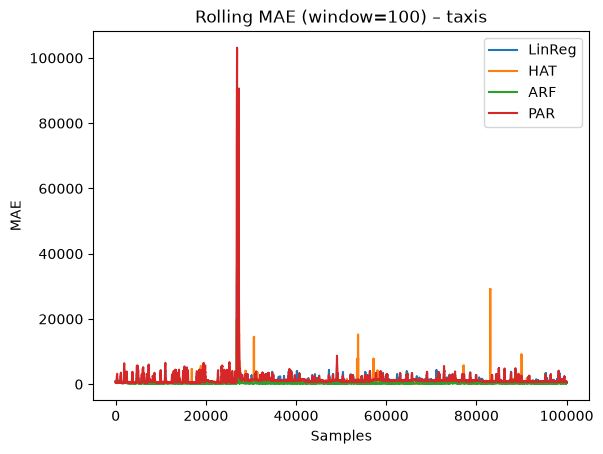

In [14]:
name, params = 'taxis', streams['taxis']

models = {
    'LinReg': compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                preprocessing.TargetStandardScaler(linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01)))),
    'HAT':    compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                tree.HoeffdingAdaptiveTreeRegressor(seed=42)),
    'ARF':    compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                forest.ARFRegressor(seed=42)),
    'PAR': compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                preprocessing.TargetStandardScaler(linear_model.PARegressor(C=0.01, mode=2, eps=0.1))
    )
}

for model_name, model in models.items():
    plt.plot(rolling_mae_curve(model, params['stream']), label=model_name)

plt.title(f'Rolling MAE (window=100) – {name}')
plt.xlabel('Samples'); plt.ylabel('MAE'); plt.legend(); plt.show()

/var/folders/vl/d0smtcsj2rx2x02_smfdy5_w0000gn/T/ipykernel_7195/217504642.py:2: DeprecationWarning: Passing an instance to utils.Rolling is deprecated and will be removed in a future release. Pass the class and forward constructor kwargs instead, e.g. utils.Rolling(stats.Mean, window_size=...) or utils.Rolling(stats.Var, window_size=..., ddof=0).
  m = utils.Rolling(metrics.MAE(), window_size=window)


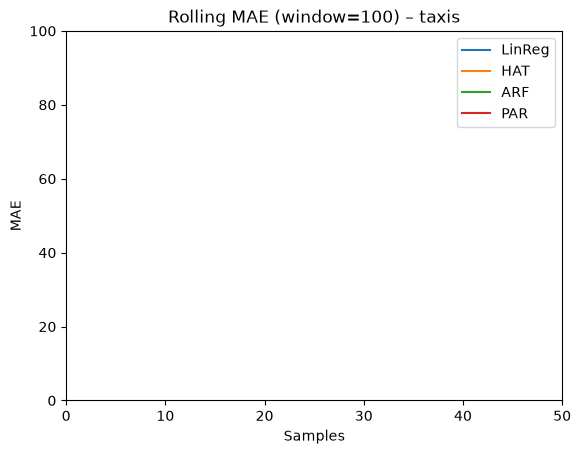

In [16]:
# Visualizing early training
name, params = 'taxis', streams['taxis']

models = {
    'LinReg': compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                preprocessing.TargetStandardScaler(linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01)))),
    'HAT':    compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                tree.HoeffdingAdaptiveTreeRegressor(seed=42)),
    'ARF':    compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                forest.ARFRegressor(seed=42)),
    'PAR': compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                preprocessing.TargetStandardScaler(linear_model.PARegressor(C=0.01, mode=2, eps=0.1))
    )
}

for model_name, model in models.items():
    plt.plot(rolling_mae_curve(model, params['stream']), label=model_name)

plt.title(f'Rolling MAE (window=100) – {name}')
plt.xlabel('Samples');plt.xlim(0, 50); plt.ylim(0, 100); plt.ylabel('MAE'); plt.legend(); plt.show()

In [ ]:
name, params = 'bikes', streams['bikes']

models = {
    'LinReg': compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                preprocessing.TargetStandardScaler(linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01)))),
    'HAT':    compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                tree.HoeffdingAdaptiveTreeRegressor(seed=42)),
    'ARF':    compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                forest.ARFRegressor(seed=42)),
    'PAR': compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                preprocessing.TargetStandardScaler(linear_model.PARegressor(C=0.01, mode=2, eps=0.1))
    )
}

for model_name, model in models.items():
    plt.plot(rolling_mae_curve(model, params['stream']), label=model_name)

plt.title(f'Rolling MAE (window=500) – {name}')
plt.xlabel('Samples'); plt.ylabel('MAE'); plt.legend(); plt.show()

In [ ]:
name, params = 'stocks', streams['stocks']

models = {
    'LinReg': compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                preprocessing.TargetStandardScaler(linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01)))),
    'HAT':    compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                tree.HoeffdingAdaptiveTreeRegressor(seed=42)),
    'ARF':    compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                forest.ARFRegressor(seed=42)),
    'PAR': compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                preprocessing.TargetStandardScaler(linear_model.PARegressor(C=0.01, mode=2, eps=0.1))
    )
}

for model_name, model in models.items():
    plt.plot(rolling_mae_curve(model, params['stream']), label=model_name)

plt.title(f'Rolling MAE (window=500) – {name}')
plt.xlabel('Samples'); plt.ylabel('MAE'); plt.legend(); plt.show()

In [ ]:
name, params = 'friedman', streams['friedman']

models = {
    'LinReg': compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                preprocessing.TargetStandardScaler(linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01)))),
    'HAT':    compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                tree.HoeffdingAdaptiveTreeRegressor(seed=42)),
    'ARF':    compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                forest.ARFRegressor(seed=42)),
    'PAR': compose.Pipeline(params['features_processor'](), preprocessing.StandardScaler(),
                preprocessing.TargetStandardScaler(linear_model.PARegressor(C=0.01, mode=2, eps=0.1))
    )
}

for model_name, model in models.items():
    plt.plot(rolling_mae_curve(model, params['stream']), label=model_name)

for p in (3_000, 7_000):        
    plt.axvline(p, color='grey', ls='--')

plt.title(f'Rolling MAE (window=500) – {name}')
plt.xlabel('Samples'); plt.ylabel('MAE'); plt.legend(); plt.show()

### Drift Detection

#### Comparaison of ADWIN, PageHinkley KSWIN methods on the 4 datasets

In [ ]:
reg_drift_models = {'ADWIN': drift.ADWIN(), 'PageHinkley': drift.PageHinkley(), 'KSWIN': drift.KSWIN(seed=42)}

for name, detector in reg_drift_models.items():
    for stream, params in streams.items(): 
        mae, rmse, r2 = metrics.MAE(), metrics.RMSE(), metrics.R2()
        model = compose.Pipeline(
            params['features_processor'](),
            preprocessing.StandardScaler(),
            preprocessing.TargetStandardScaler(
            linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01)))
        )
        drifts = []
        for i, (x, y) in enumerate(taxis):
            y_pred = model.predict_one(x)
            model.learn_one(x, y)
            detector.update(abs(y - y_pred))
            if detector.drift_detected:
                drifts.append(i)

        print(f"Model {name} | Dataset {params['stream']}: {len(drifts)} drifts, first ones: {drifts[:10]}")

In [92]:
# Taxis 

reg_drift_models = {'ADWIN': drift.ADWIN(), 'PageHinkley': drift.PageHinkley(), 'KSWIN': drift.KSWIN(seed=42)}

for name, detector in reg_drift_models.items():
    model = compose.Pipeline(
        ('features', compose.FuncTransformer(date_preprocess_taxis)
         + (compose.Select('store_and_fwd_flag') | preprocessing.OneHotEncoder())),
        ('scale', preprocessing.StandardScaler()),
        ('lin_reg', linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01)))
    )
    
    drifts = []
    for i, (x, y) in enumerate(taxis):
        y_pred = model.predict_one(x)
        model.learn_one(x, y)
        detector.update(abs(y - y_pred))
        if detector.drift_detected:
            drifts.append(i)

    print(f"{name}: {len(drifts)} drifts, first ones: {drifts[:10]}")

ADWIN: 2061 drifts, first ones: [1055, 1183, 1823, 2271, 3487, 4607, 5631, 8511, 8575, 9887]
PageHinkley: 48621 drifts, first ones: [29, 59, 89, 119, 149, 179, 209, 239, 269, 299]
KSWIN: 5220 drifts, first ones: [237, 337, 917, 1064, 1169, 1810, 1910, 2341, 2460, 3462]


In [93]:
# Bikes 

reg_drift_models = {'ADWIN': drift.ADWIN(), 'PageHinkley': drift.PageHinkley(), 'KSWIN': drift.KSWIN(seed=42)}

for name, detector in reg_drift_models.items():
    model = compose.Pipeline(
    ('features', compose.FuncTransformer(date_preprocess_bikes)
     + (compose.Select('station', 'description') | preprocessing.OneHotEncoder())),
    ('scale', preprocessing.StandardScaler()),
    ('lin_reg', linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01)))
    )
    
    drifts = []
    for i, (x, y) in enumerate(bikes):
        y_pred = model.predict_one(x)
        model.learn_one(x, y)
        detector.update(abs(y - y_pred))
        if detector.drift_detected:
            drifts.append(i)

    print(f"{name}: {len(drifts)} drifts, first ones: {drifts[:10]}")


Caching the list of root modules, please wait!
(This will only be done once - type '%rehashx' to reset cache!)

ADWIN: 574 drifts, first ones: [767, 959, 1663, 1823, 1951, 2175, 2367, 2559, 2719, 3039]
PageHinkley: 1885 drifts, first ones: [121, 287, 435, 669, 752, 870, 971, 1159, 1215, 1436]
KSWIN: 1121 drifts, first ones: [110, 229, 405, 541, 641, 749, 892, 992, 1102, 1231]


In [ ]:
# Stocks 

reg_drift_models = {'ADWIN': drift.ADWIN(), 'PageHinkley': drift.PageHinkley(), 'KSWIN': drift.KSWIN(seed=42)}

for name, detector in reg_drift_models.items():
    model = compose.Pipeline(
    ('scale', preprocessing.StandardScaler()),
    ('lin_reg', linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01)))
    )
    
    drifts = []
    for i, (x, y) in enumerate(stocks):
        y_pred = model.predict_one(x)
        model.learn_one(x, y)
        detector.update(abs(y - y_pred))
        if detector.drift_detected:
            drifts.append(i)

    print(f"{name}: {len(drifts)} drifts, first ones: {drifts[:10]}")

In [ ]:
# Synthetic Friedman 

reg_drift_models = {'ADWIN': drift.ADWIN(), 'PageHinkley': drift.PageHinkley(), 'KSWIN': drift.KSWIN(seed=42)}

for name, detector in reg_drift_models.items():
    model = compose.Pipeline(
    ('scale', preprocessing.StandardScaler()),
    ('lin_reg', linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01)))
    )
    
    drifts = []
    for i, (x, y) in enumerate(friedman):
        y_pred = model.predict_one(x)
        model.learn_one(x, y)
        detector.update(abs(y - y_pred))
        if detector.drift_detected:
            drifts.append(i)

    print(f"{name}: {len(drifts)} drifts, first ones: {drifts[:10]}")

#### Effect of drift handling

## Classification